# 03 - Feature Engineering

Every idea is **tested before it is kept**. A quick 5-fold cross-validation score (Linear Regression and XGBoost, MAE) is computed for each option, and only changes that help, or simplify without hurting, go into the final dataset.

Sections:
1. Redundant columns (heatmap)
2. Skewness
3. Outliers
4. Bias in the data
5. New features from EDA
6. Encoding: one-hot vs ordinal vs frequency vs target encoding
7. Target transform
8. Summary and final dataset

Input: `data/processed/cleaned.csv` → Output: `data/processed/features.csv`

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

sns.set(style="darkgrid")

In [2]:
df = pd.read_csv('data/processed/cleaned.csv')
y = df['spend_next_month']
df.shape

(24750, 42)

### Helper - quick score for any version of the features

In [3]:
results = []

def evaluate(name, X, target_encode=None, target_transform=None):
    """5-fold CV MAE for Linear Regression and XGBoost. Lower is better."""
    X = X.drop(columns='spend_next_month', errors='ignore')
    row = {'Experiment': name}
    for model_name, model in [('Linear Regression', make_pipeline(StandardScaler(), LinearRegression())),
                              ('XGBoost', XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42))]:
        if target_encode:   # encoder is fit inside each fold -> no leakage
            model = make_pipeline(ColumnTransformer([('te', TargetEncoder(random_state=42), target_encode)],
                                                    remainder='passthrough'), model)
        if target_transform == 'sqrt':
            model = TransformedTargetRegressor(model, func=np.sqrt, inverse_func=np.square)
        if target_transform == 'log':
            model = TransformedTargetRegressor(model, func=np.log1p, inverse_func=np.expm1)
        mae = -cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=42),
                               scoring='neg_mean_absolute_error').mean()
        row[model_name] = round(mae, 2)
    results.append(row)
    return row

def onehot(X):
    return pd.get_dummies(X, drop_first=True, dtype=int)

evaluate('Baseline (cleaned data, one-hot)', onehot(df))

{'Experiment': 'Baseline (cleaned data, one-hot)',
 'Linear Regression': np.float64(110.56),
 'XGBoost': np.float64(98.32)}

## 1. Redundant Columns

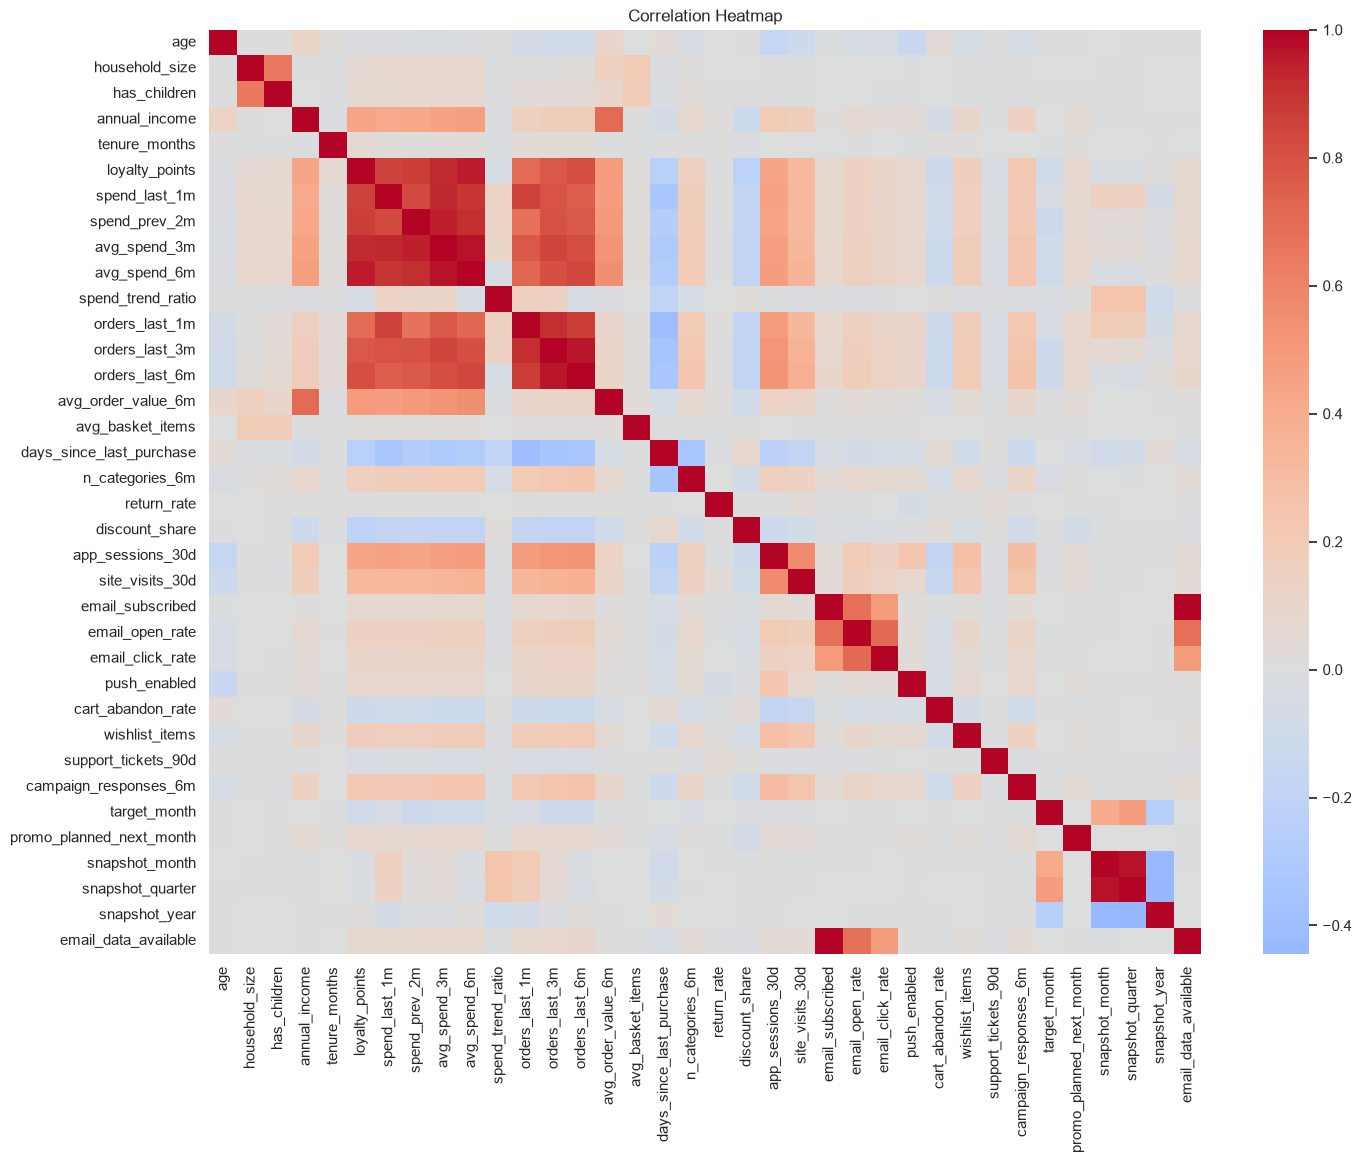

In [4]:
num = df.select_dtypes('number').drop(columns='spend_next_month')
corr = num.corr()
plt.figure(figsize=(16,12))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap')
plt.show()

In [5]:
# pairs of columns that are almost the same (|corr| > 0.9)
pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs[pairs > 0.9].sort_values(ascending=False).to_frame('abs corr')

,,abs corr
email_subscribed,email_data_available,1.000000
avg_spend_3m,avg_spend_6m,0.970018
snapshot_month,snapshot_quarter,0.969450
orders_last_3m,orders_last_6m,0.962925
loyalty_points,avg_spend_6m,0.954817
spend_prev_2m,avg_spend_3m,0.945053
spend_last_1m,avg_spend_3m,0.929827
loyalty_points,avg_spend_3m,0.924354
orders_last_1m,orders_last_3m,0.915333
spend_prev_2m,avg_spend_6m,0.910885


In [6]:
# avg_order_value_6m looks like it is simply calculated from two other columns
calc = df['avg_spend_6m'] * 6 / df['orders_last_6m']
print('corr(avg_order_value_6m, avg_spend_6m*6/orders_last_6m) =', round(df['avg_order_value_6m'].corr(calc), 4))

corr(avg_order_value_6m, avg_spend_6m*6/orders_last_6m) = 1.0


In [7]:
# columns added in preprocessing that repeat information we already have
print('snapshot_month == target_month - 1       :', ((df['snapshot_month'] % 12) + 1 == df['target_month']).mean())
print('snapshot_quarter == ceil(snapshot_month/3):', (df['snapshot_quarter'] == (df['snapshot_month'] + 2) // 3).mean())
print('email_data_available == email_subscribed  :', (df['email_data_available'] == df['email_subscribed']).mean())

snapshot_month == target_month - 1       : 1.0
snapshot_quarter == ceil(snapshot_month/3): 1.0
email_data_available == email_subscribed  : 1.0


In [8]:
redundant = ['avg_order_value_6m', 'avg_spend_3m', 'orders_last_3m', 'loyalty_points']
evaluate('Drop avg_order_value_6m', onehot(df.drop(columns=['avg_order_value_6m'])))
evaluate('Drop all 4 highly correlated columns', onehot(df.drop(columns=redundant)))

{'Experiment': 'Drop all 4 highly correlated columns',
 'Linear Regression': np.float64(110.74),
 'XGBoost': np.float64(98.3)}

**Finding**
- `avg_order_value_6m` is an exact formula of `avg_spend_6m` and `orders_last_6m` (corr 1.0). It adds nothing, so it is **dropped**.
- Three columns from preprocessing repeat existing ones 100% of the time, so they are **dropped**: `snapshot_month` (always `target_month` − 1), `snapshot_quarter` (just the month grouped by 3) and `email_data_available` (identical to `email_subscribed`). `snapshot_year` is new information, so it is kept.
- The spend columns (1m, 2m, 3m, 6m, loyalty points) and the order columns (1m, 3m, 6m) are 0.9+ correlated. Dropping them did **not** help (the scores above), because each covers a slightly different time window. They are **kept**. Trees handle correlated columns fine, and the only model hurt by multicollinearity is Linear Regression, which is only the baseline.

## 2. Skewness

In [9]:
skew = num.skew().sort_values(ascending=False)
skew.to_frame('skew').head(12)

,skew
days_since_last_purchase,4.501254
loyalty_points,2.893675
spend_last_1m,2.506488
spend_prev_2m,2.475801
avg_spend_3m,2.368174
avg_spend_6m,2.333393
orders_last_3m,2.064636
orders_last_1m,2.050701
orders_last_6m,1.999005
spend_trend_ratio,1.968263


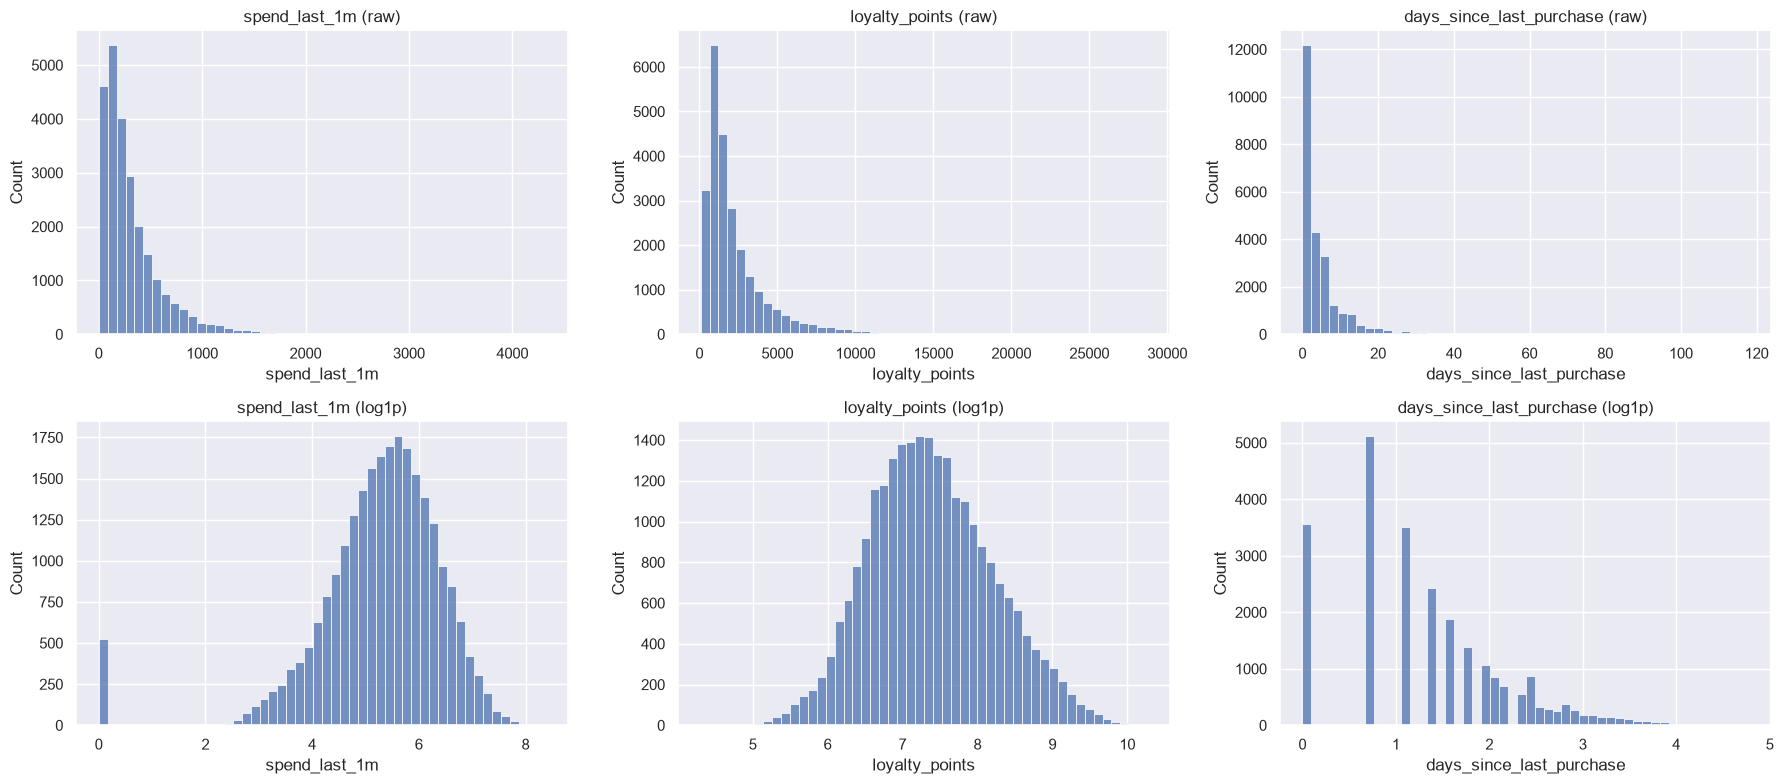

In [10]:
cols = ['spend_last_1m', 'loyalty_points', 'days_since_last_purchase']
fig, axes = plt.subplots(2, 3, figsize=(18,8))
for i, col in enumerate(cols):
    sns.histplot(df[col], bins=50, ax=axes[0, i]).set_title(f'{col} (raw)')
    sns.histplot(np.log1p(df[col]), bins=50, ax=axes[1, i]).set_title(f'{col} (log1p)')
plt.tight_layout()
plt.show()

In [11]:
skewed = [c for c in num.columns if num[c].skew() > 1 and num[c].min() >= 0]
df_log = df.copy()
df_log[skewed] = np.log1p(df_log[skewed])
print(len(skewed), 'skewed columns:', skewed)
evaluate('log1p on skewed columns', onehot(df_log))

18 skewed columns: ['annual_income', 'tenure_months', 'loyalty_points', 'spend_last_1m', 'spend_prev_2m', 'avg_spend_3m', 'avg_spend_6m', 'spend_trend_ratio', 'orders_last_1m', 'orders_last_3m', 'orders_last_6m', 'avg_order_value_6m', 'avg_basket_items', 'days_since_last_purchase', 'return_rate', 'app_sessions_30d', 'email_click_rate', 'support_tickets_90d']


{'Experiment': 'log1p on skewed columns',
 'Linear Regression': np.float64(129.53),
 'XGBoost': np.float64(98.32)}

**Finding**
- 18 columns are right-skewed (skew > 1). Recency is the worst (4.5), followed by loyalty points (2.9) and the spend columns (about 2.4).
- log1p makes them look normal, but it **hurts Linear Regression a lot** (MAE 110.6 → 129.5) and does nothing for XGBoost. Spend next month is roughly a *straight-line* function of past spend in raw units, and the log bends that line. Tree models only care about the order of values, so the log doesn't change them.
- So **no log transform** on features.

## 3. Outliers

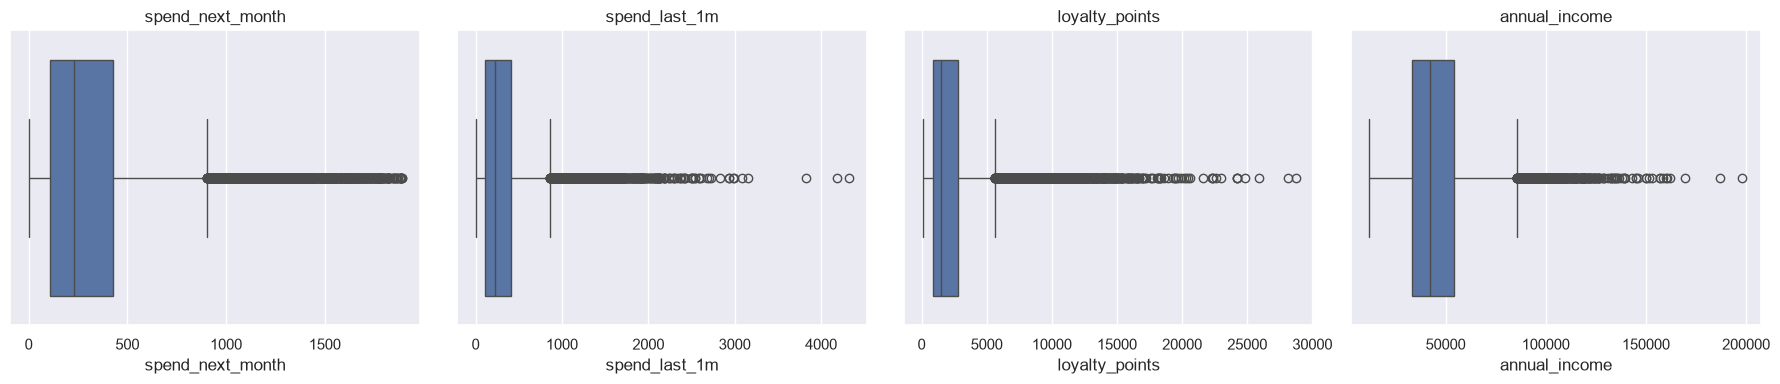

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18,4))
for ax, col in zip(axes, ['spend_next_month', 'spend_last_1m', 'loyalty_points', 'annual_income']):
    sns.boxplot(x=df[col], ax=ax).set_title(col)
plt.tight_layout()
plt.show()

In [13]:
# cap every continuous column at its 1st and 99th percentile
cont = [c for c in num.columns if num[c].nunique() > 15]
df_clip = df.copy()
df_clip[cont] = df_clip[cont].clip(df[cont].quantile(0.01), df[cont].quantile(0.99), axis=1)
evaluate('Clip outliers at 1% / 99%', onehot(df_clip))

{'Experiment': 'Clip outliers at 1% / 99%',
 'Linear Regression': np.float64(109.43),
 'XGBoost': np.float64(98.38)}

**Finding**
- The extreme top 1% of spenders were already **dropped in 01 - Preprocessing**, so the target now tops out at about 1,889 (median about 227). The boxplots still show long right tails in the features.
- Capping the features at the 1st/99th percentile helps **Linear Regression** a little (110.6 → 109.4), because straight-line models are pulled around by extreme values. It does **not** help **XGBoost** (98.32 → 98.38), our main model, since trees split on order and don't care how far out a value is.
- So **no further capping**. It would only help the baseline, and every capped value is a real customer's real number.

## 4. Bias in the Data

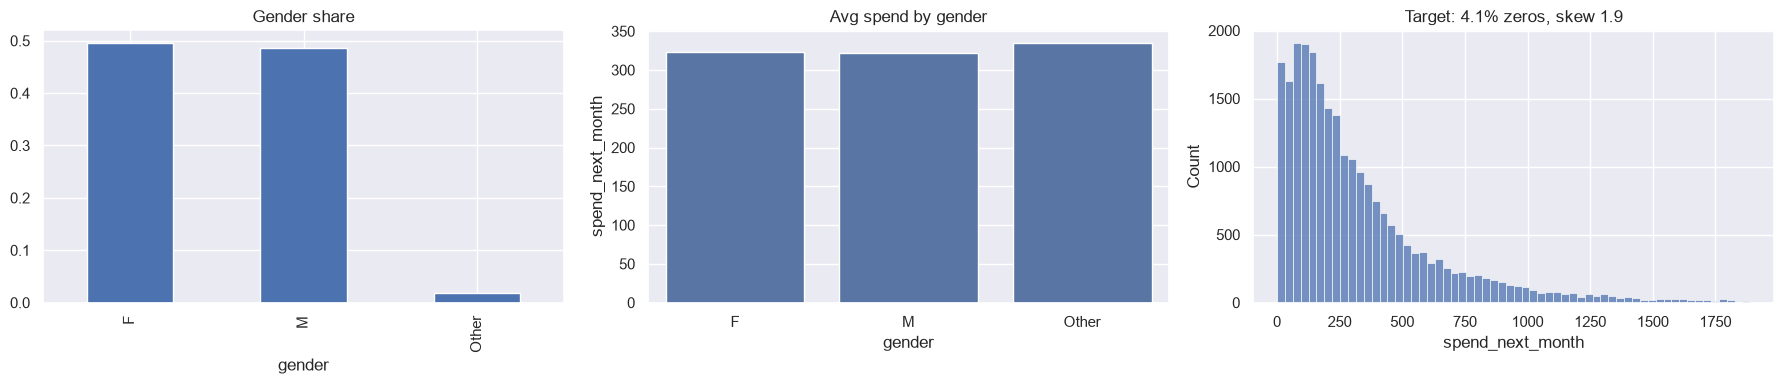

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
df['gender'].value_counts(normalize=True).plot(kind='bar', ax=axes[0], title='Gender share')
sns.barplot(data=df, x='gender', y='spend_next_month', ax=axes[1], errorbar=None).set_title('Avg spend by gender')
sns.histplot(y, bins=60, ax=axes[2]).set_title(f'Target: {(y == 0).mean():.1%} zeros, skew {y.skew():.1f}')
plt.tight_layout()
plt.show()

In [15]:
print('education missing (now Unknown):', (df['education'] == 'Unknown').mean().round(3))
print('email rates missing only for unsubscribed customers:',
      (df.loc[df['email_subscribed'] == 0, 'email_open_rate'] == 0).all())
evaluate('Drop gender', onehot(df.drop(columns=['gender'])))

education missing (now Unknown): 0.038
email rates missing only for unsubscribed customers: True


{'Experiment': 'Drop gender',
 'Linear Regression': np.float64(110.55),
 'XGBoost': np.float64(98.28)}

**Finding**
- **Gender**: average spend is almost the same for F and M (about 323), and the ANOVA test in EDA found no significant difference (p = 0.11). "Other" is only 1.9% of customers, so its average is unreliable. Gender adds no predictive value and is a sensitive attribute, so it is **dropped** to avoid building gender bias into the model.
- **Target**: still right-skewed (skew 1.85 after dropping the top 1%) with 4.1% zeros, meaning some customers buy nothing. This is handled in section 7.
- **Missing values**: the email rates are missing only for unsubscribed customers, and `email_subscribed` already captures that. `education` is missing for 4%, so a flag `education_unknown` keeps that information when education becomes a number (section 6).

## 5. New Features from EDA

In [16]:
fe = df.drop(columns=['avg_order_value_6m', 'gender', 'snapshot_month', 'snapshot_quarter', 'email_data_available'])

# spending more or less than usual?
fe['spend_momentum'] = fe['spend_last_1m'] / (fe['avg_spend_6m'] + 1)
# average spend per order last month
fe['spend_per_order_1m'] = fe['spend_last_1m'] / (fe['orders_last_1m'] + 1)
# recency flags (EDA: spend drops sharply after 7 and 30 days)
fe['recent_buyer'] = (fe['days_since_last_purchase'] <= 7).astype(int)
fe['inactive_30d'] = (fe['days_since_last_purchase'] > 30).astype(int)
# holiday season (EDA: Nov & Dec spend more)
fe['holiday_month'] = fe['target_month'].isin([11, 12]).astype(int)
# promo works more on price-sensitive customers
fe['promo_x_discount'] = fe['promo_planned_next_month'] * fe['discount_share']
# total online engagement
fe['total_engagement'] = fe['app_sessions_30d'] + fe['site_visits_30d']
# income per household member
fe['income_per_member'] = fe['annual_income'] / fe['household_size']

evaluate('Drop redundant + gender, add 8 new features', onehot(fe))

{'Experiment': 'Drop redundant + gender, add 8 new features',
 'Linear Regression': np.float64(109.26),
 'XGBoost': np.float64(97.96)}

## 6. Encoding Categorical Columns

| Encoding | How it works | Good for |
|---|---|---|
| **One-hot** | one 0/1 column per category | nominal categories with few values |
| **Ordinal** | categories → ordered numbers (Basic=0, Silver=1, Gold=2) | categories with a natural order |
| **Frequency** | category → how often it appears | many categories, when popularity matters |
| **Target encoding** | category → average target for that category, fit inside each CV fold so the answer doesn't leak in (the CatBoost-style idea, in sklearn's `TargetEncoder`) | high-cardinality categories (zip codes, product ids) |

In [17]:
cats = ['region', 'education', 'membership_tier', 'preferred_channel']
for c in cats:
    print(c, '->', df[c].nunique(), 'categories')

region -> 3 categories
education -> 5 categories
membership_tier -> 3 categories
preferred_channel -> 3 categories


In [18]:
ordinal_maps = {
    'membership_tier': {'Basic': 0, 'Silver': 1, 'Gold': 2},
    'education': {'High school': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3},
}

def ordinal(X):
    X = X.copy()
    X['education_unknown'] = (X['education'] == 'Unknown').astype(int)
    X['education'] = X['education'].replace('Unknown', 'Bachelor')   # missing -> most common level
    for c, m in ordinal_maps.items():
        X[c] = X[c].map(m)
    return X

def frequency(X):
    X = X.copy()
    for c in cats:
        X[c] = X[c].map(X[c].value_counts(normalize=True))
    return X

evaluate('Encoding: one-hot all', onehot(fe))
evaluate('Encoding: ordinal (tier, education) + one-hot rest', onehot(ordinal(fe)))
evaluate('Encoding: frequency', frequency(fe))
evaluate('Encoding: target encoding', fe, target_encode=cats)
evaluate('Encoding: ordinal + target encoding rest', ordinal(fe), target_encode=['region', 'preferred_channel'])

{'Experiment': 'Encoding: ordinal + target encoding rest',
 'Linear Regression': np.float64(109.27),
 'XGBoost': np.float64(98.07)}

**Finding**
- All encodings score within about 0.1 MAE of each other, so there is no real winner on accuracy. With only 3-5 categories per column, every method can capture the same information.
- Target encoding is the most advanced option, but it only pays off with **many** categories (hundreds). It also adds risk: if it isn't fit inside each fold, the target leaks into the features.
- Chosen: **ordinal** for `membership_tier` and `education` (they have a real order, Gold > Silver > Basic and PhD > Master > ...) plus **one-hot** for `region` and `preferred_channel` (no order). This is simple, safe, and easy to explain.

## 7. Target Transform (skewed target)

In [19]:
final = onehot(ordinal(fe))
evaluate('Final features + sqrt(target)', final, target_transform='sqrt')
evaluate('Final features + log1p(target)', final, target_transform='log')
pd.DataFrame(results).tail(3)

,Experiment,Linear Regression,XGBoost
11,Encoding: ordinal + target encoding rest,109.27,98.07
12,Final features + sqrt(target),107.38,97.59
13,Final features + log1p(target),162.43,102.03


**Finding**
- Training on `sqrt(spend)` and squaring the predictions back lowers MAE a little (XGBoost 97.96 → 97.59), because the model stops chasing the biggest spenders. That gain is well within the noise between CV folds, and an earlier check on the full data showed sqrt also lowered R2 and made the ANN worse.
- log1p is clearly worse: squashing the target too hard makes the model under-predict big spenders.
- **Kept the raw target.** This keeps every model and the app simple. sqrt is a good thing to revisit if MAE becomes the only metric that matters.

## 8. Summary and Final Dataset

In [20]:
summary = pd.DataFrame(results).drop_duplicates('Experiment').set_index('Experiment')
summary

,Linear Regression,XGBoost
Experiment,,
"Baseline (cleaned data, one-hot)",110.56,98.32
Drop avg_order_value_6m,110.73,98.24
Drop all 4 highly correlated columns,110.74,98.30
log1p on skewed columns,129.53,98.32
Clip outliers at 1% / 99%,109.43,98.38
Drop gender,110.55,98.28
"Drop redundant + gender, add 8 new features",109.26,97.96
Encoding: one-hot all,109.26,97.96
"Encoding: ordinal (tier, education) + one-hot rest",109.28,98.01


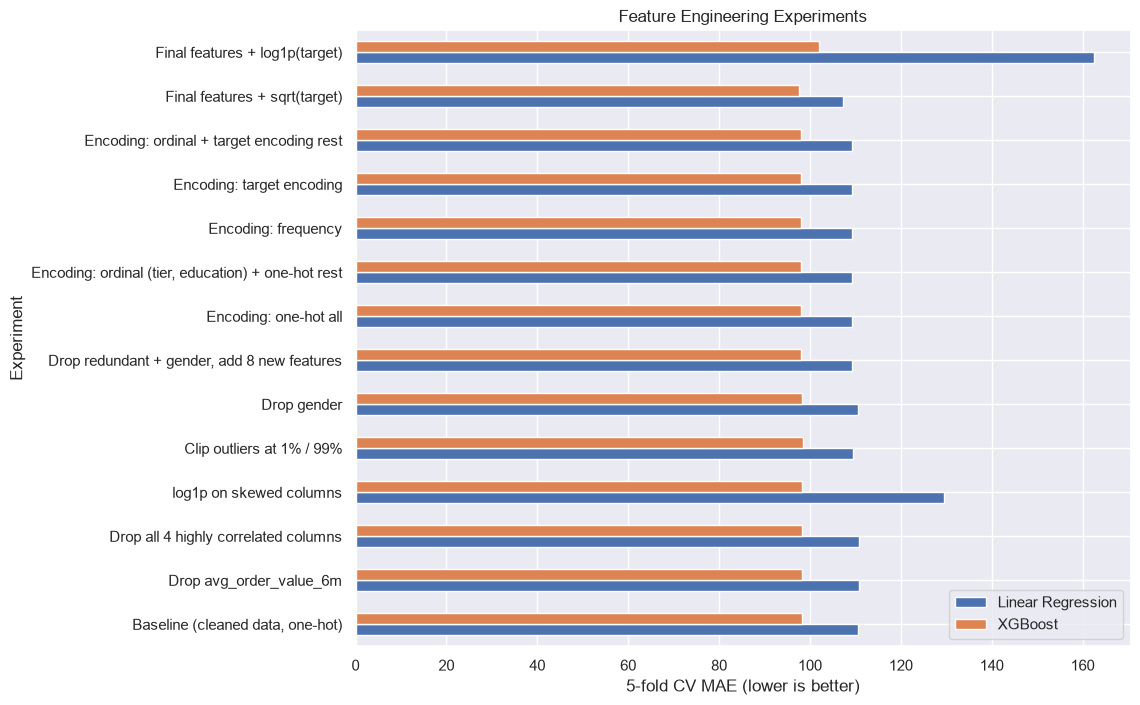

In [21]:
summary.plot(kind='barh', figsize=(10,8))
plt.xlabel('5-fold CV MAE (lower is better)')
plt.title('Feature Engineering Experiments')
plt.show()

| Step | Decision | Why |
|---|---|---|
| Redundant columns | drop `avg_order_value_6m`, `snapshot_month`, `snapshot_quarter`, `email_data_available` | exact copies or formulas of other columns |
| Correlated spend/order columns | keep | dropping them didn't help |
| Skewed features | no transform | log hurt Linear Regression; trees don't care |
| Outliers | top 1% of spend dropped in 01, no feature capping | capping helped only Linear Regression, not XGBoost |
| Gender | drop | no signal, sensitive attribute |
| Missing education | `education_unknown` flag | keeps the information after ordinal encoding |
| New features | 8 added from EDA | recency, momentum, holiday, promo, engagement |
| Encoding | ordinal tier/education, one-hot region/channel | all encodings tie, so pick the simplest correct one |
| Target | raw | sqrt gain too small vs its trade-offs |

In [22]:
final = onehot(ordinal(fe))
final.to_csv('data/processed/features.csv', index=False)
final.shape

(24750, 48)